<center> <p style="text-align:center;font-family:arial"> <b>Universidade Federal de Alagoas</b></p>


<p style="text-align:center;font-family:arial"> <b>Instituto de Computação - PPGI - IC</b></p>


<p style="text-align:center;font-family:arial"> <b>Processamento de Linguagem Natural</b></p></center>


<p style="font-family:arial">Professor: Thales Vieira</p>

<p style="font-family:arial">Aluno: Edvonaldo Horácio dos Santos ( matrícula 2022104210)</p>

<center><p style="text-align:center;font-family:arial"> <b>4ª Lista de Exercícios</>

# Questão 1

### Libs

In [ ]:
# Import libs
import os
import re
import time
import nltk
import random
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nltk.tokenize import RegexpTokenizer
from google.colab import drive

In [ ]:
# Tempo de execução
def seconds_transform(seconds_time):
  hours = int(seconds_time/3600)
  rest_1 = seconds_time%3600
  minutes = int(rest_1/60)
  seconds = rest_1 - 60*minutes
  print("Time: ", (hours), "h ", (minutes), "min ", round(seconds,2), " s")

In [ ]:
# Mount drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = '/content/drive/MyDrive/dataset_pln_2022.2/corpus_bcc.csv'
#path = '../../MyDrive/dataset_pln_2022.2/corpus_bbc.csv'

df_corpus = pd.read_csv(path, sep=';')
print("Shape dataframe: ", df_corpus.shape)
df_corpus.describe()

Shape dataframe:  (2225, 4)


,Unnamed: 0,id
count,2225.000000,2225.000000
mean,225.321798,226.321798
std,134.218688,134.218688
min,0.000000,1.000000
25%,111.000000,112.000000
50%,222.000000,223.000000
75%,333.000000,334.000000
max,510.000000,511.000000


In [ ]:
df_corpus.groupby(by=['label']).count()

,Unnamed: 0,id,content
label,,,
business,510,510,510
entertainment,386,386,386
politics,417,417,417
sport,511,511,511
tech,401,401,401


### Pré-processamento

In [ ]:
def remove_punctuation(text):
  return  re.sub('[%s]' % re.escape(string.punctuation), ' ', text)

df_corpus['content'] = df_corpus['content'].apply(remove_punctuation) # Removendo pontuação

In [ ]:
df_corpus = df_corpus.replace(to_replace=r'\w*\d\w*', value='', regex=True) # Removendo números

In [ ]:
for i in range(df_corpus['content'].shape[0]): # Todas lowercase
  df_corpus['content'][i] = df_corpus['content'][i].lower()

df_corpus.head()

<ipython-input-8-9033f14d61c3>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_corpus['content'][i] = df_corpus['content'][i].lower()


,Unnamed: 0,id,content,label
0,0,1,ad sales boost time warner profit\n\nquarterly...,business
1,1,2,dollar gains on greenspan speech\n\nthe dollar...,business
2,2,3,yukos unit buyer faces loan claim\n\nthe owner...,business
3,3,4,high fuel prices hit ba s profits\n\nbritish a...,business
4,4,5,pernod takeover talk lifts domecq\n\nshares in...,business


In [ ]:
n_samples = 100 # Porque 12 GB de RAM não deu
df_business = df_corpus.loc[df_corpus['label'] == 'business']
df_sport = df_corpus.loc[df_corpus['label'] == 'sport']

frames = [df_business.sample(n = n_samples, random_state = 42), df_sport.sample(n = n_samples, random_state = 42)]

df_corpus_bin = pd.concat(frames)

df_corpus_bin.groupby(by=['label']).count()

,Unnamed: 0,id,content
label,,,
business,100,100,100
sport,100,100,100


In [ ]:
df_corpus_bin['label'] = df_corpus_bin['label'].replace(to_replace = 'business', value = 0)
df_corpus_bin['label'] = df_corpus_bin['label'].replace(to_replace =  'sport', value = 1)
df_corpus_bin.groupby(by = ['label']).count()

,Unnamed: 0,id,content
label,,,
0,100,100,100
1,100,100,100


## (a) Problema de classificação (binária) da 2ª lista usando uma combinação do DistilBERT com os três classificadores

Separar textos de BUSINESS de textos de SPORT

In [ ]:
# Instalando transforms lib
!pip install transformers

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 5.8 MB 12.7 MB/s 
     |████████████████████████████████| 7.6 MB 59.0 MB/s 
     |████████████████████████████████| 182 kB 87.7 MB/s 


In [ ]:
from sklearn.model_selection import train_test_split as tts
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression as LR
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import torch
import transformers as ppb
import warnings
warnings.filterwarnings('ignore')

In [ ]:
model_class, tokenizer_class, pretrained_weights = (ppb.DistilBertModel, ppb.DistilBertTokenizer, 'distilbert-base-uncased')
#model_class, tokenizer_class, pretrained_weights = (ppb.BertModel, ppb.BertTokenizer, 'bert-base-uncased')

tokenizer = tokenizer_class.from_pretrained(pretrained_weights)
model = model_class.from_pretrained(pretrained_weights)

Downloading:   0%|          | 0.00/232k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/483 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of the model checkpoint at distilbert-base-uncased were not used when initializing DistilBertModel: ['vocab_layer_norm.bias', 'vocab_projector.weight', 'vocab_projector.bias', 'vocab_transform.bias', 'vocab_layer_norm.weight', 'vocab_transform.weight']
- This IS expected if you are initializing DistilBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DistilBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [ ]:
type(tokenizer)

transformers.models.distilbert.tokenization_distilbert.DistilBertTokenizer

### Tokenizando

In [ ]:
tokenized = df_corpus_bin['content'].apply((lambda x: tokenizer.encode(x, add_special_tokens = True, truncation = True, max_length = 511)))

In [ ]:
print("Length: ", len(tokenized))
print("Type: ", type(tokenized))

Length:  200
Type:  <class 'pandas.core.series.Series'>


In [ ]:
#print(tokenized[0])
tokenized.head()

480    [101, 4234, 4341, 5409, 2144, 2866, 7027, 4341...
449    [101, 2149, 7027, 4341, 12058, 1999, 2285, 214...
475    [101, 8174, 13316, 6895, 1055, 6661, 2061, 290...
434    [101, 6469, 2015, 23311, 8406, 1999, 4511, 857...
368    [101, 5404, 5016, 26436, 2845, 3813, 16005, 50...
Name: content, dtype: object

### Padding

In [ ]:
max_len = 0

for i in tokenized.values:
  if len(i) > max_len:
    max_len = len(i)

In [ ]:
padded = np.array([i + [0]*(max_len - len(i)) for i in tokenized.values])

In [ ]:
np.array(padded).shape

(200, 511)

### Masking

In [ ]:
attention_mask = np.where(padded != 0, 1, 0)
attention_mask.shape

(200, 511)

### Using DistilBERT: Deep Learning

In [ ]:
start_dist_bert = time.time()

inputs_ids = torch.tensor(padded)
attention_mask = torch.tensor(attention_mask)

with torch.no_grad():
  last_hidden_states = model(inputs_ids, attention_mask = attention_mask)

sec_dist_bert = (time.time() - start_dist_bert)
seconds_transform(sec_dist_bert)

Time:  0 h  7 min  51.8  s


### Features and labels

In [ ]:
features = last_hidden_states[0][:, 0, :].numpy()

labels = df_corpus_bin['label']

In [ ]:
X_train_bert, X_test_bert, y_train_bert, y_test_bert = tts(features, labels, test_size = 0.3, random_state = 42)

In [ ]:
print("Shape X_train: ", X_train_bert.shape)
print("Shape y_train: ", y_train_bert.shape)

Shape X_train:  (140, 768)
Shape y_train:  (140,)


### Regressão Logística

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_bert = LogisticRegression()

In [ ]:
lr_bert.fit(X_train_bert, y_train_bert)

y_pred_bert_lr = lr_bert.predict(X_test_bert)

#### Avaliando Logistic Regression

In [ ]:
# Setp 5 - Evaluate Logistic Regression
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_lr_bert = confusion_matrix(y_test_bert, y_pred_bert_lr)

In [ ]:
sport_true = int(0)
sport_pred_bert_lr = int(0)
business_true = int(0)
business_pred_bert_lr = int(0)

for idx, cont in enumerate(y_test_bert):
  if cont == 1: # Sport
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_bert_lr):
  if cont2 == 1:
    sport_pred_bert_lr = sport_pred_bert_lr + 1
  else:
    business_pred_bert_lr = business_pred_bert_lr + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_bert_lr)
print("Business pred ", business_pred_bert_lr)
print("Confusion matrix: Logistic Regression")
print(cm_lr_bert)

Sport true:  29
Business true:  31
Sport pred:  29
Business pred  31
Confusion matrix: Logistic Regression
[[31  0]
 [ 0 29]]


In [ ]:
group_names_lr_bert = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_lr_bert = ["{0:0.0f}".format(value) for value in cm_lr_bert.flatten()]

group_per_lr_bert = ["{0:.2%}".format(value) for value in cm_lr_bert.flatten()/np.sum(cm_lr_bert)]

labels_lr_bert = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_lr_bert, group_counts_lr_bert, group_per_lr_bert)]

labels_lr_bert = np.asarray(labels_lr_bert).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

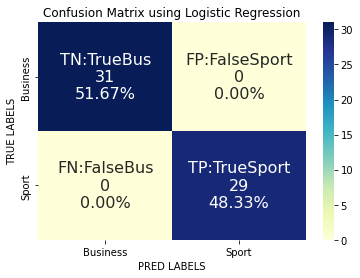

In [ ]:
ax = plt.subplot()
sns.heatmap(cm_lr_bert, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_lr_bert, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax)
ax.set_title('Confusion Matrix using Logistic Regression')
ax.set_xlabel('PRED LABELS');ax.set_ylabel('TRUE LABELS')

In [ ]:
# Função para calcular métricas
def calc_metrics(tp, tn, fp, fn):
  accuracy = (tp + tn)/(tp + fp + tn + fn)
  precision = (tp)/(tp + fp)
  recall = (tp) / (tp + fn)
  f1_score = 2 * (precision * recall) / (precision + recall)

  return accuracy, precision, recall, f1_score

In [ ]:
tp_lr_bert = 29
tn_lr_bert = 31
fp_lr_bert = 0
fn_lr_bert = 0

acc_bert_lr, prec_bert_lr, recall_bert_lr, f1_score_bert_lr = calc_metrics(tp_lr_bert, tn_lr_bert, fp_lr_bert, fn_lr_bert)

print("/-- Métricas: Regressão Logística com DistilBERT --/")
print("Acurácia: ", round(lr_bert.score(X_test_bert, y_pred_bert_lr)))
print("Precisão: ", round(prec_bert_lr, 4))# tp / (tp + fp)
print("Recall: ", round(recall_bert_lr, 4))
print("F1-score: ", round(f1_score_bert_lr, 4))

/-- Métricas: Regressão Logística com DistilBERT --/
Acurácia:  1
Precisão:  1.0
Recall:  1.0
F1-score:  1.0


### Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_bert = GaussianNB()

In [ ]:
nb_bert.fit(X_train_bert, y_train_bert)

y_pred_bert_nb = nb_bert.predict(X_test_bert)

#### Avaliando Naive Bayes

In [ ]:
cm_nb_bert = confusion_matrix(y_test_bert, y_pred_bert_nb)

In [ ]:
sport_true = int(0)
sport_pred_bert_nb = int(0)
business_true = int(0)
business_pred_bert_nb = int(0)

for idx, cont in enumerate(y_test_bert):
  if cont == 1: # Sport
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_bert_nb):
  if cont2 == 1:
    sport_pred_bert_nb = sport_pred_bert_nb + 1
  else:
    business_pred_bert_nb = business_pred_bert_nb + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_bert_lr)
print("Business pred ", business_pred_bert_lr)
print("Confusion matrix: Naive Bayes com DistilBERT")
print(cm_nb_bert)

Sport true:  29
Business true:  31
Sport pred:  29
Business pred  31
Confusion matrix: Naive Bayes com DistilBERT
[[31  0]
 [ 0 29]]


In [ ]:
group_names_nb_bert = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_nb_bert = ["{0:0.0f}".format(value) for value in cm_nb_bert.flatten()]

group_per_nb_bert = ["{0:.2%}".format(value) for value in cm_nb_bert.flatten()/np.sum(cm_nb_bert)]

labels_nb_bert = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_nb_bert, group_counts_nb_bert, group_per_nb_bert)]

labels_nb_bert = np.asarray(labels_nb_bert).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

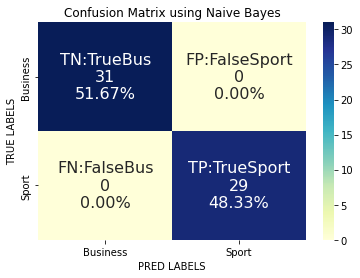

In [ ]:
ax = plt.subplot()
sns.heatmap(cm_nb_bert, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_nb_bert, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax)
ax.set_title('Confusion Matrix using Naive Bayes')
ax.set_xlabel('PRED LABELS');ax.set_ylabel('TRUE LABELS')

In [ ]:
tp_nb_bert = 29
tn_nb_bert = 31
fp_nb_bert = 0
fn_nb_bert = 0

acc_bert_nb, prec_bert_nb, recall_bert_nb, f1_score_bert_nb = calc_metrics(tp_nb_bert, tn_nb_bert, fp_nb_bert, fn_nb_bert)

print("/-- Métricas: Naive Bayes com DistilBERT --/")
print("Acurácia: ", round(nb_bert.score(X_test_bert, y_pred_bert_nb)))
print("Precisão: ", round(prec_bert_nb, 4))# tp / (tp + fp)
print("Recall: ", round(recall_bert_nb, 4))
print("F1-score: ", round(f1_score_bert_nb, 4))

/-- Métricas: Regressão Logística com DistilBERT --/
Acurácia:  1
Precisão:  1.0
Recall:  1.0
F1-score:  1.0


### SVM

In [ ]:
from sklearn.svm import SVC

svm_bert = SVC()

In [ ]:
svm_bert.fit(X_train_bert, y_train_bert)

y_pred_bert_svm = svm_bert.predict(X_test_bert)

#### Avaliando SVM

In [ ]:
cm_svm_bert = confusion_matrix(y_test_bert, y_pred_bert_svm)

In [ ]:
sport_true = int(0)
sport_pred_bert_svm = int(0)
business_true = int(0)
business_pred_bert_svm = int(0)

for idx, cont in enumerate(y_test_bert):
  if cont == 1: # Sport
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_bert_svm):
  if cont2 == 1:
    sport_pred_bert_svm = sport_pred_bert_svm + 1
  else:
    business_pred_bert_svm = business_pred_bert_svm + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_bert_svm)
print("Business pred ", business_pred_bert_svm)
print("Confusion matrix: SVM com DistilBERT")
print(cm_svm_bert)

Sport true:  29
Business true:  31
Sport pred:  29
Business pred  31
Confusion matrix: SVM com DistilBERT
[[31  0]
 [ 0 29]]


In [ ]:
group_names_svm_bert = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_svm_bert = ["{0:0.0f}".format(value) for value in cm_svm_bert.flatten()]

group_per_svm_bert = ["{0:.2%}".format(value) for value in cm_svm_bert.flatten()/np.sum(cm_svm_bert)]

labels_svm_bert = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_svm_bert, group_counts_svm_bert, group_per_svm_bert)]

labels_svm_bert = np.asarray(labels_svm_bert).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

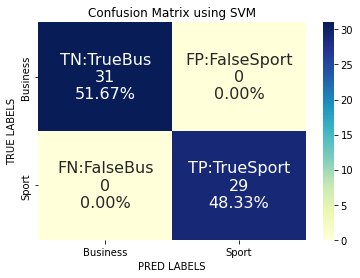

In [ ]:
ax = plt.subplot()
sns.heatmap(cm_svm_bert, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_svm_bert, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax)
ax.set_title('Confusion Matrix using SVM')
ax.set_xlabel('PRED LABELS');ax.set_ylabel('TRUE LABELS')

In [ ]:
tp_svm_bert = 29
tn_svm_bert = 31
fp_svm_bert = 0
fn_svm_bert = 0

acc_bert_svm, prec_bert_svm, recall_bert_svm, f1_score_bert_svm = calc_metrics(tp_svm_bert, tn_svm_bert, fp_svm_bert, fn_svm_bert)

print("/-- Métricas: SVM com DistilBERT --/")
print("Acurácia: ", round(svm_bert.score(X_test_bert, y_pred_bert_svm)))
print("Precisão: ", round(prec_bert_svm, 4))# tp / (tp + fp)
print("Recall: ", round(recall_bert_svm, 4))
print("F1-score: ", round(f1_score_bert_svm, 4))

/-- Métricas: SVM com DistilBERT --/
Acurácia:  1
Precisão:  1.0
Recall:  1.0
F1-score:  1.0


## (b) Comparar os resultados do item anterior e da 2ª lista

Mesmo tomando um subconjunto com 100 de cada label, os resultados de todos os algoritmos usando o DistilBERT foi superior em todas as métricas.

# Questão 2

## (a) Extrair os tópicos da base usando [BERT Topic](https://github.com/MaartenGr/BERTopic)

In [ ]:
# Instalando o BERT Topic
!pip install bertopic

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 90 kB 5.6 MB/s 
     |████████████████████████████████| 88 kB 8.3 MB/s 
     |████████████████████████████████| 85 kB 5.3 MB/s 
     |████████████████████████████████| 662 kB 65.4 MB/s 
     |████████████████████████████████| 5.2 MB 68.1 MB/s 
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
    Preparing wheel metadata ... done
     |████████████████████████████████| 1.3 MB 62.1 MB/s 
     |████████████████████████████████| 1.1 MB 61.9 MB/s 
  Created wheel for hdbscan: filename=hdbscan-0.8.29-cp38-cp38-linux_x86_64.whl size=2700837 sha256=2d9a9eee1b46a4f81a8356a93b9a093a1f4bf62963932558a3b5baf551b7955f
  Stored in directory: /root/.cache/pip/wheels/76/06/48/527e038689c581cc9e519c73840efdc7473805149e55bd7ffd
  Created wheel for sentence-transformers: filename=sentence_transformers-2.2.2-py3-none-any.whl size=1

In [ ]:
docs_bbc_news = df_corpus['content']

In [ ]:
type(docs_bbc_news)

pandas.core.series.Series

In [ ]:
from bertopic import BERTopic

topic_model_bbc_news = BERTopic(language="english", calculate_probabilities=True, verbose=True)

topics_bbc_news, probs_bbc_news = topic_model_bbc_news.fit_transform(docs_bbc_news)

Downloading:   0%|          | 0.00/1.18k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/190 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/10.6k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/612 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/116 [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/39.3k [00:00<?, ?B/s]

... (6 outputs left out)

Downloading:   0%|          | 0.00/232k [00:00<?, ?B/s]

Downloading:   0%|          | 0.00/349 [00:00<?, ?B/s]

Batches:   0%|          | 0/70 [00:00<?, ?it/s]

2022-12-03 00:24:09,098 - BERTopic - Transformed documents to Embeddings
2022-12-03 00:24:23,855 - BERTopic - Reduced dimensionality
2022-12-03 00:24:24,183 - BERTopic - Clustered reduced embeddings


In [ ]:
topic_model_bbc_news.get_topic(0)

[('he', 0.019020948656829937),
 ('we', 0.01861965512893738),
 ('club', 0.017205064804802057),
 ('the', 0.016890100447996475),
 ('to', 0.016647932860631494),
 ('but', 0.015727856420661365),
 ('and', 0.015351193939099138),
 ('chelsea', 0.015306865786472633),
 ('his', 0.014672712262255281),
 ('united', 0.013762222814015268)]

In [ ]:
topic_model_bbc_news.get_topic(0)[2][0]

'club'

In [ ]:
type(topic_model_bbc_news)

bertopic._bertopic.BERTopic

In [ ]:
# Exibindo palavras mais frequentes de 5 tópicos
for i in range(0, 5):
  print("/-- WORDS OF TOPIC {val} --/".format(val = i))
  for j in range(0, 10):
    print(topic_model_bbc_news.get_topic(i)[j][0])
  #print("\n")

/-- WORDS OF TOPIC 0 --/
he
we
club
the
to
but
and
chelsea
his
united
/-- WORDS OF TOPIC 1 --/
film
best
the
and
in
of
for
actor
awards
films
/-- WORDS OF TOPIC 2 --/
to
mobile
the
of
and
is
are
that
in
it
/-- WORDS OF TOPIC 3 --/
england
wales
ireland
rugby
the
and
in
but
to
we
/-- WORDS OF TOPIC 4 --/
music
band
album
the
and
best
in
song
of
was


## (b) Exibir vizualizações com gráficos de barra (vizualize_barchart()) e visualize_topics()

In [ ]:
df_corpus.groupby(by=['label']).count()

,Unnamed: 0,id,content
label,,,
business,510,510,510
entertainment,386,386,386
politics,417,417,417
sport,511,511,511
tech,401,401,401


#### Com barchart

In [ ]:
# Vizualizando as palavras mais frequentes através de um barchart
topic_model_bbc_news.visualize_barchart(top_n_topics = 5)

#### Com visualize_topics()

In [ ]:
# Visualizando tópicos - mapa de distância e frequência
topic_model_bbc_news.visualize_topics(top_n_topics = 10)

# Questão 3: Organizar os principais resultados obtidos --> vídeo

## (a) Lista 1: Questões 6, 7 e 8

## (b) Lista 2: Questões 2, 3, 4 e 5

## (c) Lista 3: Questões 2 e 4

## (d) Lista 4: Questões 1 e 2